In [89]:
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt
import requests
import pandas as pd

In [90]:
# read in curb spaces from the Seattle ArcGIS API (paged, server returns max 2000 rows per request)
import pandas as pd

URL = ("https://services.arcgis.com/ZOyb2t4B0UYuYNYH/arcgis/rest/services/"
       "Curb_Space_Categories/FeatureServer/6/query")

# rows per request; the server won't return more than its max at once
PAGE_SIZE = 2000

pages = []
offset = 0
while True:
    r = requests.get(URL, params={
        "where": "1=1",
        "outFields": "*", # return all columns
        "f": "geojson",  # response format: GeoJSON
        "orderByFields": "OBJECTID",
        "resultOffset": offset, # skip this many rows (start of this page)
        "resultRecordCount": PAGE_SIZE, # how many rows to return in this page
    }, timeout=60)
    r.raise_for_status()
    data = r.json()
    if "error" in data:
        raise RuntimeError(data["error"])
    if not data["features"]:
        break
    pages.append(gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:4326"))
    offset += PAGE_SIZE

gis_curb_spaces = pd.concat(pages, ignore_index=True)
print(gis_curb_spaces.shape)

# Coordinate Reference System
print(gis_curb_spaces.crs) 
# CRS defines how the numbers in geometry map to real locations on earth

print(gis_curb_spaces.columns.tolist())

gis_curb_spaces.head()

(40516, 28)
EPSG:4326
['geometry', 'OBJECTID', 'BLOCKID', 'BLOCK_ST', 'BLOCK_END', 'WIDTH_OFFSET', 'GEOBASYS', 'SPACELENGTH', 'SPACETYPE', 'SPACETYPEDESC', 'TIME_LIMIT', 'SPACE_NB', 'CATEGORY', 'SIDE', 'CURRENT_STATUS', 'ELMNTKEY', 'SPACEKEY', 'SEGKEY', 'PRIMARYDISTRICTCD', 'SECONDARYDISTRICTCD', 'OVERRIDEYN', 'OVERRIDECOMMENT', 'PAIDAREA', 'SUBAREA', 'UNIQUEID', 'STOPSTATUS', 'STOP_STATUS_DESCRIPTION', 'Shape__Length']


,geometry,OBJECTID,BLOCKID,BLOCK_ST,BLOCK_END,WIDTH_OFFSET,GEOBASYS,SPACELENGTH,SPACETYPE,SPACETYPEDESC,...,PRIMARYDISTRICTCD,SECONDARYDISTRICTCD,OVERRIDEYN,OVERRIDECOMMENT,PAIDAREA,SUBAREA,UNIQUEID,STOPSTATUS,STOP_STATUS_DESCRIPTION,Shape__Length
0,"LINESTRING (-122.33435 47.59251, -122.33435 47...",567506,S01-08,1077.0,1084.0,-39,None,7,CLR,CLEARANCE,...,DISTRICT1,,N,None,Pioneer Square,Edge,None,,None,6.997605
1,"LINESTRING (-122.34477 47.61458, -122.34481 47...",567507,03-22,393.0,404.0,30,None,11,XW,CROSSWALK,...,DISTRICT7,,N,None,Belltown,South,None,,None,10.996132
2,"LINESTRING (-122.33406 47.59608, -122.33406 47...",567508,S01-05,143.0,182.0,33,None,39,NP,NO PARKING,...,DISTRICT1,,N,None,Pioneer Square,Edge,None,,None,38.899409
3,"LINESTRING (-122.31255 47.62357, -122.31255 47...",567509,EE15-05,113.0,130.0,-17,None,17,PS,PAY STATION,...,DISTRICT3,,N,None,15th Avenue E,None,None,,None,16.978526
4,"LINESTRING (-122.33828 47.60844, -122.3383 47....",567510,02-14,83.0,89.0,32,None,6,CLR,CLEARANCE,...,DISTRICT7,,N,None,Commercial Core,Retail,None,,None,5.998672


In [91]:
print(gis_curb_spaces[['SPACETYPE', 'SPACETYPEDESC']].drop_duplicates().sort_values('SPACETYPE').reset_index(drop=True).to_string())


   SPACETYPE                       SPACETYPEDESC
0      ALLEY                               ALLEY
1         BA                        BARRIER AREA
2       BIKE                           BIKE ZONE
3        BUS                            BUS ZONE
4     BUSLAY                    BUS LAYOVER ZONE
5      CHRTR                    CHARTER BUS ZONE
6        CLR                           CLEARANCE
7         CR                           CURB RAMP
8     CRBBLB                           CURB BULB
9       CRPL         CARPOOL PARKING - FULL TIME
10        CS                    CARSHARE/FLEXCAR
11      CVLZ        COMMERCIAL VEHICLE LOAD ZONE
12    CVLZ-B                     CVLZ - BUS ZONE
13    CVLZ-P                          CVLZ - PLZ
14        CZ                      CONSULATE ZONE
15    DISABL                       DISABLED ZONE
16        DW                            DRIVEWAY
17       HYD                             HYDRANT
18      L/UL                    LOAD/UNLOAD ZONE
19    L/UL-P        

In [92]:
# check space type 
print(gis_curb_spaces['SPACETYPEDESC'].value_counts().to_string())

SPACETYPEDESC
CLEARANCE                             9856
PAY STATION                           9302
CROSSWALK                             3664
NO PARKING                            3617
DRIVEWAY                              2070
CURB RAMP                             1438
PAY STATION - RES PARKING ZONE        1385
NOT A DESIGNATED CROSSWALK            1123
CURB BULB                             1098
LOAD/UNLOAD ZONE                       848
TOW AWAY ZONE                          794
PASSENGER LOAD ZONE                    719
ALLEY                                  472
COMMERCIAL VEHICLE LOAD ZONE           413
UNRESTRICTED                           395
PAY STATION - TEMP REMOVAL             371
TIME LIMIT - RES PARKING ZONE          359
HYDRANT                                317
BARRIER AREA                           311
BUS ZONE                               289
TIME LIMIT                             257
DISABLED ZONE                          200
PAY STATION - BUS LAYOVER              1

General load/unload (4) – 935

LOAD/UNLOAD ZONE – 848
PAY STATION - LOAD/UNLOAD ZONE – 61
TIME LIMIT - LOAD/UNLOAD ZONE – 21
FULL-TIME PAID LOADING – 5

Commercial/truck (4) – 464

COMMERCIAL VEHICLE LOAD ZONE – 413
TRUCK LOAD/UNLOAD ZONE – 26
PAY STATION - CVLZ – 24
TIME LIMIT - TRUCK L/U ZONE – 1

Passenger, PLZ (4) – 831

PASSENGER LOAD ZONE – 719
PAY STATION - PLZ – 91
PASSENGER LOAD ZONE - VENDING ZONE – 12
TIME LIMIT - PLZ – 9

Shared/hybrid (2) – 46

CVLZ - PLZ – 44
CVLZ - BUS ZONE – 2

*NEED TO FIGURE OUT WHAT THE LAWS ARE LIKE FOR EACH TYPE*

In [93]:
# group loading zone types (from the markdown cell above) by SPACETYPEDESC
LOADING_GROUPS = {
    "General load/unload": ["LOAD/UNLOAD ZONE", "PAY STATION - LOAD/UNLOAD ZONE",
                            "TIME LIMIT - LOAD/UNLOAD ZONE", "FULL-TIME PAID LOADING"],
    "Commercial/truck": ["COMMERCIAL VEHICLE LOAD ZONE", "TRUCK LOAD/UNLOAD ZONE",
                         "PAY STATION - CVLZ", "TIME LIMIT - TRUCK L/U ZONE"],
    "Passenger (PLZ)": ["PASSENGER LOAD ZONE", "PAY STATION - PLZ",
                        "PASSENGER LOAD ZONE - VENDING ZONE", "TIME LIMIT - PLZ"],
    "Shared/hybrid": ["CVLZ - PLZ", "CVLZ - BUS ZONE"],
}

# reverse lookup: description -> group name
desc_to_group = {d: g for g, descs in LOADING_GROUPS.items() for d in descs}

gis_loading = gis_curb_spaces[gis_curb_spaces["SPACETYPEDESC"].isin(desc_to_group)].copy()
gis_loading["zone_group"] = gis_loading["SPACETYPEDESC"].map(desc_to_group)

print(gis_loading.shape)
print(gis_loading["zone_group"].value_counts())

(2276, 29)
zone_group
General load/unload    935
Passenger (PLZ)        831
Commercial/truck       464
Shared/hybrid           46
Name: count, dtype: int64


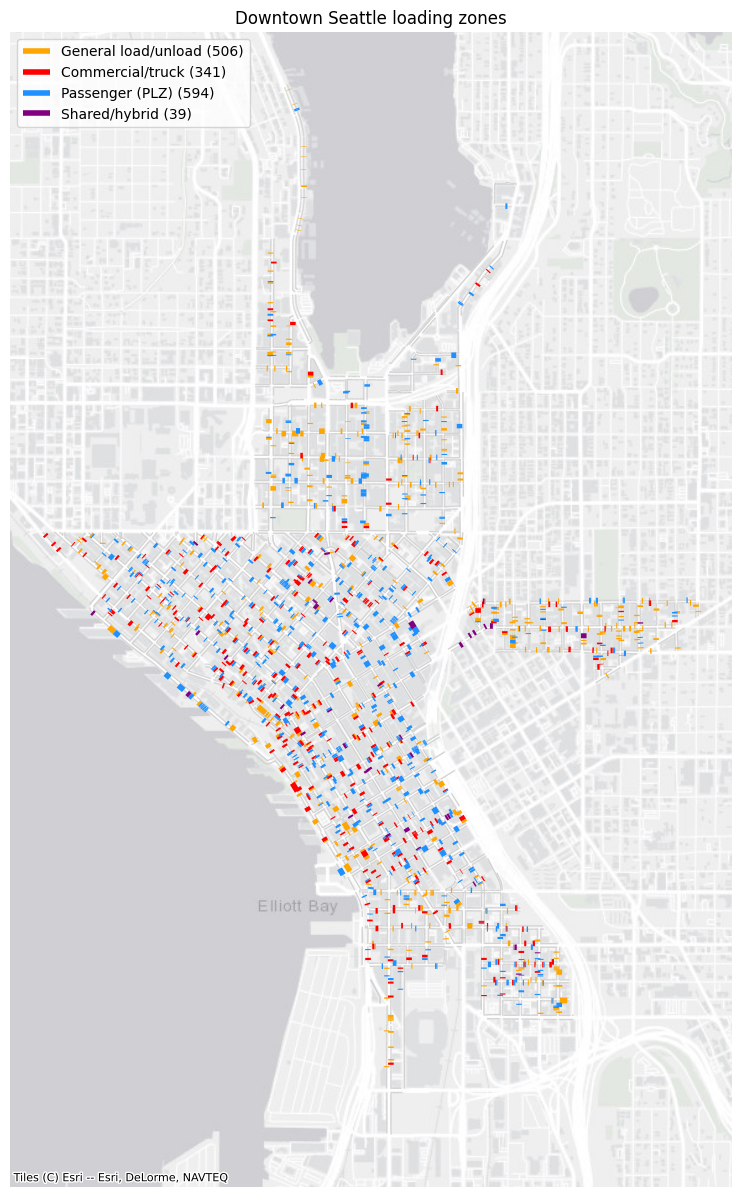

In [94]:
# map loading zones; edit DOWNTOWN_AREAS (PAIDAREA values) to define the study area
DOWNTOWN_AREAS = ["Belltown", "Commercial Core", "Denny Triangle", "Pioneer Square",
                  "South Lake Union", "Pike-Pine", "Chinatown/ID", "Westlake Ave N"]

COLORS = {"General load/unload": "orange", "Commercial/truck": "red",
          "Passenger (PLZ)": "dodgerblue", "Shared/hybrid": "purple"}

# basemap tiles are in Web Mercator (EPSG:3857), so reproject before plotting
dt_all = gis_curb_spaces[gis_curb_spaces["PAIDAREA"].isin(DOWNTOWN_AREAS)].to_crs(epsg=3857)
dt_load = gis_loading[gis_loading["PAIDAREA"].isin(DOWNTOWN_AREAS)].to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(15, 15))
dt_all.plot(ax=ax, color="lightgray", linewidth=1)  # all curb space as context
for group, color in COLORS.items():
    sub = dt_load[dt_load["zone_group"] == group]
    sub.plot(ax=ax, color=color, linewidth=4, label=f"{group} ({len(sub)})")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.legend(loc="upper left")
ax.set_axis_off()
ax.set_title("Downtown Seattle loading zones")
plt.show()

# SMART PROJECT DATA

## Data loading

In [95]:
# read in 3 rounds of data
idax_1 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 1 Data Collection.csv')
idax_2 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 2 Data Collection.csv')
idax_3 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 3 Data Collection.csv')

print(idax_1.head())
print(idax_2.head())
print(idax_3.head())

   Event_NB  IDAX_Site_NB  ufl_block_id ufl_blockface_id  \
0         1             1            87             87SW   
1         2             1            87             87SW   
2         3             1            87             87SW   
3         4             1            87             87SW   
4         5             1            87             87SW   

                                 unitdesc BLOCK_ID  ELMNTKEY SPACETYPE  \
0  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
1  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
2  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713       PLZ   
3  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
4  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   

  SPACE_NB Concatenated_SPACE_NB  ... activity_type commercial_logo  \
0      -12              02-23-12  ...       Private          <null>   
1      -04              02-23-04  ...       Private 

In [96]:
# shape of the datasets

print("idax_1: ", idax_1.shape)
print("idax_2: ", idax_2.shape)
print("idax_3: ", idax_3.shape)

# given the size of the data, deep learning models (neural network) is not possible, furthermore other simpler models such as logistic regression could be tried but will require testing. 

idax_1:  (8182, 30)
idax_2:  (384, 22)
idax_3:  (263, 15)


## Data exploration

In [97]:
dfs = {"idax_1": idax_1, "idax_2": idax_2, "idax_3": idax_3}
cols = {name: set(df.columns) for name, df in dfs.items()}

all_cols = sorted(set.union(*cols.values()))
idax_columns_df_all = pd.DataFrame({name: [c in cols[name] for c in all_cols] for name in dfs}, index=all_cols)
idax_columns_df_all

,idax_1,idax_2,idax_3
BLOCK_ID,True,True,True
CVLZ_permit_vid,True,False,False
Concatenated_PRIMARY_SPACE_NB,False,True,False
Concatenated_SECONDARY_SPACE_NB,False,True,False
Concatenated_SPACE_NB,True,False,False
Curbside_Location,False,True,False
Date,True,True,True
Dwell,False,True,False
ELMNTKEY,True,True,True
Event_NB,True,True,False


In [98]:
# show just the columns that are available in all 3 in presence
idax_columns_df_all[idax_columns_df_all.all(axis=1)]

,idax_1,idax_2,idax_3
BLOCK_ID,True,True,True
Date,True,True,True
ELMNTKEY,True,True,True
SPACETYPE,True,True,True
park_end,True,True,True
park_start,True,True,True
total_duration,True,True,True
ufl_block_id,True,True,True
ufl_blockface_id,True,True,True
unitdesc,True,True,True


In [99]:
# columns needed: Block ID, Date, SPACETYPE, body_type/Vehicle_body_type, park end, park start, total duration 
# cvlz_permit_vid only avaialable in idax_1

# need to check if body_type and Vehicle_body_type is similar between the 3 dfs 
print(idax_1['body_type'].value_counts())
print(idax_2['Vehicle_Body_Type'].value_counts())
print(idax_3['body_type'].value_counts())
# the body type and vehicle body type requires remapping. unless clear mapping available can't be used

body_type
Passenger Vehicle    6858
Bus                   355
Van                   296
Bus/Other Transit     186
Single Unit Truck     177
Step-Van              107
Minivan                86
CM Pickup              80
Motorcycle             30
Trailer Truck           6
RVs                     1
Name: count, dtype: int64
Vehicle_Body_Type
Car           289
Commercial     58
Pickup         17
Van            16
Other           3
Bus             1
Name: count, dtype: int64
body_type
Passenger vehicle    212
Single Unit           15
Van                   15
Step-Van              14
CM Pick-up             3
Mini-Van               3
Motorcycle             1
Name: count, dtype: int64


Given the small size of the idax_2 and 3 and the complications from inconsistent variables/columns, I suggest dropping IDAX 2 and 3 in our analysis and model. 
Given how small the rows are it wouldn't matter too much. 

## Data slicing/cleaning

In [100]:
idax_1.columns

Index(['Event_NB', 'IDAX_Site_NB', 'ufl_block_id', 'ufl_blockface_id',
       'unitdesc', 'BLOCK_ID', 'ELMNTKEY', 'SPACETYPE', 'SPACE_NB',
       'Concatenated_SPACE_NB', 'Date', 'park_start', 'park_end',
       'total_duration', 'body_type', 'passenger_inout', 'driver_out',
       'driverout_start', 'driverout_end', 'driver_outtime', 'activity_type',
       'commercial_logo', 'load_unload', 'handcart', 'CVLZ_permit_vid',
       'permit_type', 'TNC_permit_vid', 'Unnamed: 27', 'Unnamed: 28',
       'Unnamed: 29'],
      dtype='object')

### Removing na rows/columns

In [101]:
df = idax_1.replace('<null>', pd.NA)

na_counts = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1),
})
na_counts.sort_values("missing", ascending=False)

,missing,percent
Unnamed: 27,8182,100.0
Unnamed: 28,8181,100.0
Unnamed: 29,8181,100.0
permit_type,7439,90.9
commercial_logo,6888,84.2
driver_outtime,4603,56.3
driverout_end,4364,53.3
driverout_start,4244,51.9
total_duration,662,8.1
park_end,408,5.0


In [102]:
# should drop columns with more than 50% missing data from idax_1
# should also drop rows where total_duration is missing or where park_start, park_missing data is missing as this is a required data 

# replace the text '<null>' with real missing values
idax_1_clean = idax_1.replace('<null>', pd.NA)

# 1. drop columns with more than 50% missing
missing_share = idax_1_clean.isna().mean()
dropped_cols = missing_share[missing_share > 0.5].index.tolist()
print("dropping columns:", dropped_cols)
idax_1_clean = idax_1_clean.drop(columns=dropped_cols)

# 2. drop rows missing any of the required fields
required = ['total_duration', 'park_start', 'park_end']
before = len(idax_1_clean)
idax_1_clean = idax_1_clean.dropna(subset=required)
print(f"dropped {before - len(idax_1_clean)} rows; {len(idax_1_clean)} remain")


dropping columns: ['driverout_start', 'driverout_end', 'driver_outtime', 'commercial_logo', 'permit_type', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29']
dropped 662 rows; 7520 remain


### Joining idax data to sdot gis data to get area

In [103]:
# join idax_1 to curbspaces on blockid and see paid area to see what paid area are in idax_1
gis_block_lookup = gis_curb_spaces[['BLOCKID', 'PAIDAREA']].dropna().drop_duplicates()

idax_1_area = idax_1.merge(gis_block_lookup, left_on='BLOCK_ID', right_on='BLOCKID', how='left')

print(idax_1.shape, idax_1_area.shape)  # same number of rows = no duplicates
idax_1_area['PAIDAREA'].value_counts(dropna=False)

(8182, 30) (8182, 32)


PAIDAREA
Denny Triangle    3812
Belltown          3766
NaN                604
Name: count, dtype: int64

In [104]:
# check the paidarea blockid
idax_1_area[idax_1_area['PAIDAREA'].isna()]['BLOCK_ID'].unique()

array(['53'], dtype=object)

In [105]:
x = idax_1[idax_1['BLOCK_ID'] == '53']
print(len(x))
print(x['unitdesc'].unique())        # street description
print(x['ELMNTKEY'].unique())        # street segment ID
print(x['ufl_block_id'].unique())    # note: also 53

# based on google map this is Danny Triangle

604
['7TH AVE BETWEEN BLANCHARD ST AND BELL ST']
[53433]
[53]


In [106]:
gis_curb_spaces[gis_curb_spaces['ELMNTKEY'].isin(x['ELMNTKEY'].unique())][['BLOCKID', 'PAIDAREA', 'ELMNTKEY']].drop_duplicates()
# so this should match but the BLOCKID between idax_1 and curb_space data is different 

,BLOCKID,PAIDAREA,ELMNTKEY
10310,07-22,Denny Triangle,53433


In [107]:
gis_curb_spaces[gis_curb_spaces['BLOCKID'].astype(str).str.contains(r'^53|-53$')]['BLOCKID'].unique()
# none of these matches 


array(['NW22-53', 'NWBL-53', 'NWTN-53'], dtype=object)

In [108]:
m = idax_1[idax_1['BLOCK_ID'] != '53']

print(m['ELMNTKEY'].isin(gis_curb_spaces['ELMNTKEY']).mean())   # share of IDAX rows whose ELMNTKEY exists in curb_spaces

keys_per_block = gis_curb_spaces.groupby('ELMNTKEY')['BLOCKID'].nunique()
print((keys_per_block[m['ELMNTKEY'].unique()] > 1).sum())   # keys mapping to more than one block

1.0
0


In [109]:
# ELMNTKEY better key to join than 'BLOCKID'

In [110]:
# how many idax_1 rows have an ELMNTKEY that exists in curb_spaces?
ok = idax_1_clean['ELMNTKEY'].isin(gis_curb_spaces['ELMNTKEY'])
print("rows:", len(idax_1_clean))
print("matched:", ok.sum(), "| unmatched:", (~ok).sum(), "| null keys:", idax_1_clean['ELMNTKEY'].isna().sum())

# distinct keys
print("distinct ELMNTKEY:", idax_1_clean['ELMNTKEY'].nunique(),
      "| matched:", idax_1_clean.loc[ok, 'ELMNTKEY'].nunique())
print("unmatched keys:", sorted(idax_1_clean.loc[~ok, 'ELMNTKEY'].dropna().unique()))

# left join on ELMNTKEY (overwrites the earlier BLOCK_ID-based idax_1_area)
elmnt_area = gis_curb_spaces[['ELMNTKEY', 'BLOCKID', 'PAIDAREA']].dropna().drop_duplicates()
idax_1_area = idax_1_clean.merge(elmnt_area, on='ELMNTKEY', how='left')

print("rows after merge:", len(idax_1_area), "vs", len(idax_1_clean))     # same = no duplicates
print("PAIDAREA missing:", idax_1_area['PAIDAREA'].isna().sum())
print(idax_1_area['PAIDAREA'].value_counts(dropna=False))

# where does BLOCK_ID disagree with the curb block?
print((idax_1_area['BLOCK_ID'] != idax_1_area['BLOCKID']).sum())
idax_1_area[idax_1_area['BLOCK_ID'] != idax_1_area['BLOCKID']][['BLOCK_ID', 'BLOCKID']].drop_duplicates()


rows: 7520
matched: 7520 | unmatched: 0 | null keys: 0
distinct ELMNTKEY: 28 | matched: 28
unmatched keys: []
rows after merge: 7520 vs 7520
PAIDAREA missing: 0
PAIDAREA
Denny Triangle    4139
Belltown          3381
Name: count, dtype: int64
574


,BLOCK_ID,BLOCKID
1105,53,07-22


In [111]:
# checking for missing data again
df = idax_1_area.replace('<null>', pd.NA)

na_counts = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1),
})
na_counts.sort_values("missing", ascending=False)

,missing,percent
passenger_inout,5,0.1
Event_NB,0,0.0
ufl_block_id,0,0.0
IDAX_Site_NB,0,0.0
unitdesc,0,0.0
BLOCK_ID,0,0.0
ELMNTKEY,0,0.0
ufl_blockface_id,0,0.0
SPACETYPE,0,0.0
SPACE_NB,0,0.0


### Setting up gis data to just use the data in idax

In [112]:
# street segments that exist in IDAX
idax_keys = idax_1_area['ELMNTKEY'].unique()

# curb space and loading zones on just those segments
gis_curb_idax_segments  = gis_curb_spaces[gis_curb_spaces['ELMNTKEY'].isin(idax_keys)]
gis_loading_idax_segments  = gis_loading[gis_loading['ELMNTKEY'].isin(idax_keys)]

print(len(idax_keys), "segments |", len(gis_curb_idax_segments), "curb rows |", len(gis_loading_idax_segments ), "loading zone rows")
print(gis_loading_idax_segments ['zone_group'].value_counts())


28 segments | 532 curb rows | 68 loading zone rows
zone_group
Commercial/truck       39
Passenger (PLZ)        18
General load/unload     9
Shared/hybrid           2
Name: count, dtype: int64


In [113]:
# loading zones per segment, with block and area
(gis_loading_idax_segments.groupby(['ELMNTKEY', 'BLOCKID', 'PAIDAREA', 'zone_group'])
             .size()
             .unstack('zone_group', fill_value=0))

# how many of the 28 segments have at least one loading zone
print(gis_loading_idax_segments['ELMNTKEY'].nunique(), "of", len(idax_keys), "segments have a loading zone")


28 of 28 segments have a loading zone


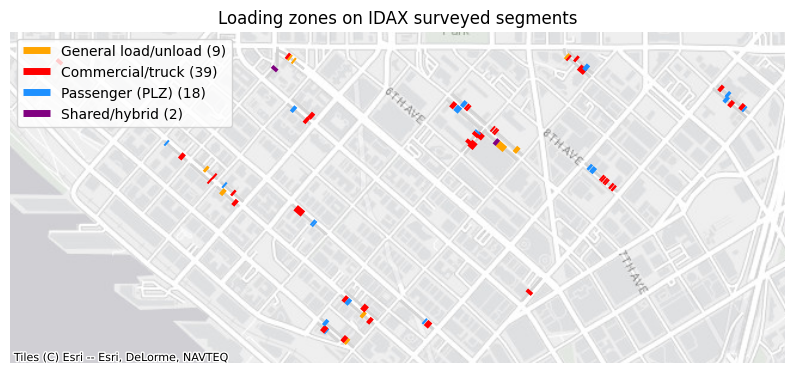

In [114]:
dt_all = gis_curb_idax_segments.to_crs(epsg=3857)
dt_load = gis_loading_idax_segments.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))
dt_all.plot(ax=ax, color="lightgray", linewidth=2)   # all curb space on the surveyed segments
for group, color in COLORS.items():
    sub = dt_load[dt_load["zone_group"] == group]
    sub.plot(ax=ax, color=color, linewidth=5, label=f"{group} ({len(sub)})")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.legend(loc="upper left")
ax.set_axis_off()
ax.set_title("Loading zones on IDAX surveyed segments")
plt.show()


#### Limitations

In [115]:
print(len(gis_loading_idax_segments) / len(gis_loading) * 100)
citywide = gis_loading['zone_group'].value_counts()
on_idax = gis_loading_idax_segments['zone_group'].value_counts()

gis_coverage = pd.DataFrame({
    "citywide": citywide,
    "on_idax_segments": on_idax,
}).fillna(0).astype(int)

gis_coverage["percent_on_idax"] = (gis_coverage["on_idax_segments"] / gis_coverage["citywide"] * 100).round(1)

# total row
gis_coverage.loc["Total"] = [
    gis_coverage["citywide"].sum(),
    gis_coverage["on_idax_segments"].sum(),
    round(gis_coverage["on_idax_segments"].sum() / gis_coverage["citywide"].sum() * 100, 1),
]

gis_coverage

2.987697715289982


,citywide,on_idax_segments,percent_on_idax
zone_group,,,
Commercial/truck,464.0,39.0,8.4
General load/unload,935.0,9.0,1.0
Passenger (PLZ),831.0,18.0,2.2
Shared/hybrid,46.0,2.0,4.3
Total,2276.0,68.0,3.0


Limitation: incomplete coverage of loading zones. The IDAX observation data covers only 28 street segments in Belltown and Denny Triangle. SDOT's citywide curb space inventory lists 2,276 loading zone records, but only 68 of them (3%) fall on the surveyed segments. For commercial and truck zones the share is 39 of 464 (8%). Our optimization model, which routes a parking enforcement officer between loading zones (a traveling salesman problem, TSP), can therefore use observed activity for only a small part of the real zone network. A route built from this data would skip many loading zones that an officer would pass or need to check, so its length, time and coverage will not match a real patrol. The results should be read as a proof of concept on the surveyed segments, not as a citywide or downtown-wide schedule.

### Removing 6pm onwards

In [116]:
# removing data from 6pm onwards
# park_start is text like '18:06:34'; '<null>' becomes missing
start = pd.to_timedelta(idax_1_area['park_start'].replace('<null>', pd.NA))

before = len(idax_1_area)
idax_1_area = idax_1_area[start < pd.Timedelta(hours=18)]
print(f"removed {before - len(idax_1_area)} rows; {len(idax_1_area)} remain")

removed 636 rows; 6884 remain


### Selecting loading zone space type

In [117]:
idax_1_area['SPACETYPE'].value_counts()

SPACETYPE
PS             1993
CVLZ           1389
PLZ             859
TRAVEL LANE     483
SBO             459
BUS             347
NP              262
TAZ             161
PS-CVLZ         153
CVLZ/PS         148
DW              140
HYD             140
L/UL            112
LOAD             58
CRB              51
XW               36
DP               21
SIDEWALK         18
ALLEY            15
CURB             13
PS-VEN           10
NP/CRB            8
CR                8
Name: count, dtype: int64

In [118]:
# select only COMMERCIAL VEHICLE LOAD ZONE, PAY STATION - CVLZ, LOAD/UNLOAD ZONE 
idax1_loading_zones = idax_1_area.copy()
idax1_loading_zones = idax_1_area[idax_1_area['SPACETYPE'].
                                          isin(['CVLZ', 
                                                'CVLZ/PS',
                                                'PS-CVLZ',
                                                'PS-VEN',
                                                'L/UL',
                                                'LOAD'
                                              ])]

## Data Analysis

### Looking at Car Body Type 

In [119]:
idax1_loading_zones.columns

Index(['Event_NB', 'IDAX_Site_NB', 'ufl_block_id', 'ufl_blockface_id',
       'unitdesc', 'BLOCK_ID', 'ELMNTKEY', 'SPACETYPE', 'SPACE_NB',
       'Concatenated_SPACE_NB', 'Date', 'park_start', 'park_end',
       'total_duration', 'body_type', 'passenger_inout', 'driver_out',
       'activity_type', 'load_unload', 'handcart', 'CVLZ_permit_vid',
       'TNC_permit_vid', 'BLOCKID', 'PAIDAREA'],
      dtype='object')

In [120]:
# check body_type 
counts = idax1_loading_zones['body_type'].value_counts(dropna=False)
pd.DataFrame({
    "count": counts,
    "percent": (counts / counts.sum() * 100).round(1),
}).style.format({"percent": "{:.1f}%"})

,count,percent
body_type,,
Passenger Vehicle,1484,79.4%
Van,145,7.8%
Single Unit Truck,92,4.9%
Step-Van,56,3.0%
Minivan,44,2.4%
CM Pickup,27,1.4%
Bus/Other Transit,16,0.9%
Motorcycle,3,0.2%
Trailer Truck,2,0.1%


In [121]:
# check body type by PAIDAREA

# counts
pd.crosstab(idax1_loading_zones['body_type'], idax1_loading_zones['PAIDAREA'])

# percent of each area's vehicles that are each body type
(pd.crosstab(idax1_loading_zones['body_type'], idax1_loading_zones['PAIDAREA'], normalize='columns') * 100).round(1)


PAIDAREA,Belltown,Denny Triangle
body_type,,
Bus,0.0,0.1
Bus/Other Transit,0.6,1.1
CM Pickup,2.3,0.7
Minivan,2.6,2.1
Motorcycle,0.2,0.1
Passenger Vehicle,74.0,84.2
Single Unit Truck,6.1,3.9
Step-Van,4.4,1.7
Trailer Truck,0.2,0.0


In [122]:
# check body type by load/unload

# counts
pd.crosstab(idax1_loading_zones['load_unload'], idax1_loading_zones['PAIDAREA'])

# percent of each area's vehicles that are each body type
(pd.crosstab(idax1_loading_zones['load_unload'], idax1_loading_zones['PAIDAREA'], normalize='columns') * 100).round(1)


PAIDAREA,Belltown,Denny Triangle
load_unload,,
No,69.4,79.3
Unclear,0.1,0.0
Yes,30.5,20.7


In [123]:
# check body type by cvlz_permit

# counts
pd.crosstab(idax1_loading_zones['CVLZ_permit_vid'], idax1_loading_zones['PAIDAREA'])

# percent of each area's vehicles that are each body type
(pd.crosstab(idax1_loading_zones['CVLZ_permit_vid'], idax1_loading_zones['PAIDAREA'], normalize='columns') * 100).round(1)


PAIDAREA,Belltown,Denny Triangle
CVLZ_permit_vid,,
No,84.6,91.8
Unclear,4.3,4.0
Yes,11.1,4.3


In [124]:
# by day
idax1_loading_zones = idax1_loading_zones.copy()
idax1_loading_zones['day'] = pd.to_datetime(idax1_loading_zones['Date']).dt.day_name()

idax1_loading_zones['day'].value_counts()

# no weekend data

day
Thursday     537
Wednesday    509
Tuesday      393
Friday       290
Monday       141
Name: count, dtype: int64

In [125]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
pd.crosstab(idax1_loading_zones['body_type'], idax1_loading_zones['day'])[order]

day,Monday,Tuesday,Wednesday,Thursday,Friday
body_type,,,,,
Bus,0,1,0,0,0
Bus/Other Transit,0,1,8,5,2
CM Pickup,0,6,12,5,4
Minivan,1,4,12,17,10
Motorcycle,0,0,2,1,0
Passenger Vehicle,133,327,390,417,217
Single Unit Truck,2,17,25,28,20
Step-Van,0,9,17,15,15
Trailer Truck,0,0,0,2,0


In [126]:
# check body type by time of day 
d = idax1_loading_zones.copy()
d['hour'] = pd.to_datetime(d['park_start'], format='%H:%M:%S', errors='coerce').dt.hour
print(d['hour'].isna().sum(), "rows without a usable park_start")
pd.crosstab(d['body_type'], d['hour'])


0 rows without a usable park_start


hour,7,8,9,10,11,12,13,14,15,16,17
body_type,,,,,,,,,,,
Bus,0,0,1,0,0,0,0,0,0,0,0
Bus/Other Transit,0,7,1,2,1,0,0,1,1,1,2
CM Pickup,3,5,3,2,1,4,3,4,1,1,0
Minivan,2,5,3,13,6,3,5,2,1,4,0
Motorcycle,0,0,0,0,0,0,0,0,2,0,1
Passenger Vehicle,72,94,129,111,168,142,147,137,150,147,187
Single Unit Truck,3,12,9,17,16,13,7,7,5,1,2
Step-Van,1,0,9,5,10,9,7,6,1,7,1
Trailer Truck,0,2,0,0,0,0,0,0,0,0,0


In [127]:
idax_loading_with_hour = idax1_loading_zones.copy()
idax_loading_with_hour['hour'] = pd.to_datetime(idax_loading_with_hour['park_start'], format='%H:%M:%S', errors='coerce').dt.hour
print(idax_loading_with_hour['hour'].isna().sum(), "rows without a usable park_start")

for area, area_rows in idax_loading_with_hour.groupby('PAIDAREA'):
    body_type_percent_by_hour = (pd.crosstab(area_rows['body_type'], area_rows['hour'], normalize='columns') * 100).round(1)
    body_type_percent_by_hour.loc['vehicles (n)'] = area_rows['hour'].value_counts().sort_index()

    print(f"\n{area} ({len(area_rows)} vehicles)")
    display(body_type_percent_by_hour)


0 rows without a usable park_start

Belltown (888 vehicles)


hour,7,8,9,10,11,12,13,14,15,16,17
body_type,,,,,,,,,,,
Bus/Other Transit,0.0,4.1,0.0,2.6,0.0,0.0,0.0,0.0,0.0,1.2,0.0
CM Pickup,0.0,6.1,2.8,2.6,0.0,4.1,2.9,4.4,1.2,1.2,0.0
Minivan,0.0,4.1,2.8,10.5,2.9,0.0,3.8,2.2,1.2,1.2,0.0
Motorcycle,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.2,0.0,1.0
Passenger Vehicle,87.1,57.1,68.1,63.2,70.5,69.4,70.5,63.7,85.0,82.7,96.0
Single Unit Truck,3.2,8.2,8.3,9.2,9.5,7.1,5.7,6.6,5.0,1.2,2.0
Step-Van,3.2,0.0,9.7,2.6,6.7,6.1,3.8,6.6,1.2,4.9,1.0
Trailer Truck,0.0,4.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Van,6.5,16.3,8.3,9.2,10.5,13.3,13.3,16.5,5.0,7.4,0.0



Denny Triangle (982 vehicles)


hour,7,8,9,10,11,12,13,14,15,16,17
body_type,,,,,,,,,,,
Bus,0.0,0.0,1.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bus/Other Transit,0.0,5.7,1.1,0.0,0.8,0.0,0.0,1.2,1.1,0.0,2.1
CM Pickup,4.8,2.3,1.1,0.0,0.8,0.0,0.0,0.0,0.0,0.0,0.0
Minivan,3.2,3.4,1.1,5.7,2.5,3.2,1.3,0.0,0.0,3.4,0.0
Motorcycle,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.1,0.0,0.0
Passenger Vehicle,71.4,75.9,84.2,72.4,77.7,78.7,92.4,94.0,92.1,90.9,95.8
Single Unit Truck,3.2,9.2,3.2,11.5,5.0,6.4,1.3,1.2,1.1,0.0,0.0
Step-Van,0.0,0.0,2.1,3.4,2.5,3.2,3.8,0.0,0.0,3.4,0.0
Van,17.5,3.4,6.3,6.9,10.7,8.5,1.3,3.6,4.5,2.3,2.1


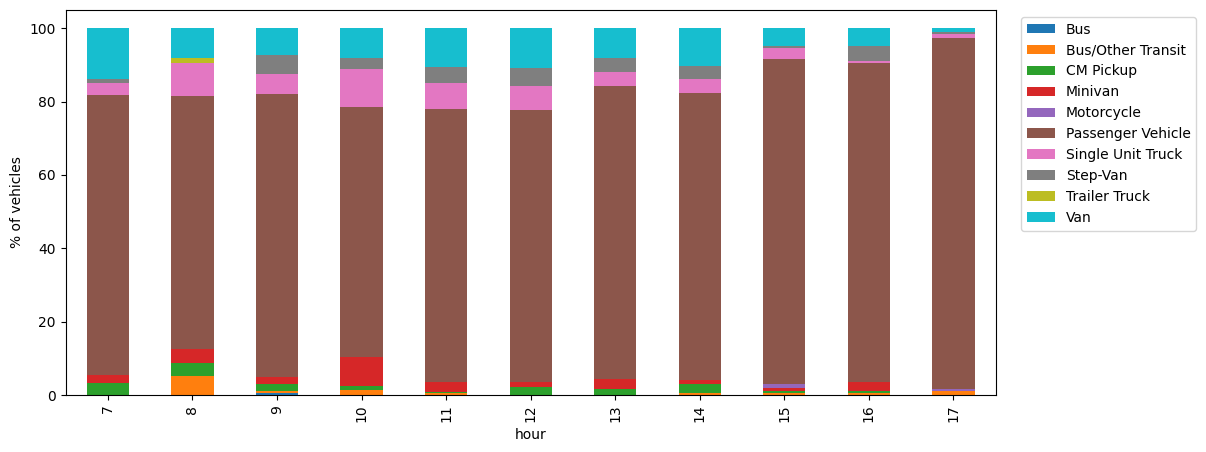

In [128]:
(pd.crosstab(d['hour'], d['body_type'], normalize='index') * 100).plot.bar(stacked=True, figsize=(12, 5))
plt.ylabel('% of vehicles')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

In [129]:
d = idax1_loading_zones.copy()

# total_duration is text like '0:18:17'; '<null>' becomes missing
d['duration_min'] = pd.to_timedelta(d['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60

summary = (d.groupby('body_type')['duration_min']
             .agg(vehicles='count',
                  total_min='sum',
                  mean_min='mean',
                  median_min='median',
                  p90_min=lambda s: s.quantile(0.9))
             .round(1)
             .sort_values('total_min', ascending=False))

summary['pct_of_total_time'] = (summary['total_min'] / summary['total_min'].sum() * 100).round(1)
summary


,vehicles,total_min,mean_min,median_min,p90_min,pct_of_total_time
body_type,,,,,,
Passenger Vehicle,1484,21132.5,14.2,4.1,29.4,63.3
Van,145,6049.2,41.7,14.7,95.7,18.1
Single Unit Truck,92,2122.9,23.1,13.9,43.6,6.4
Minivan,44,2014.3,45.8,16.0,96.6,6.0
CM Pickup,27,1003.8,37.2,19.1,53.3,3.0
Step-Van,56,904.7,16.2,10.4,27.3,2.7
Bus/Other Transit,16,94.7,5.9,0.9,17.6,0.3
Motorcycle,3,43.5,14.5,5.5,31.3,0.1
Trailer Truck,2,20.8,10.4,10.4,12.1,0.1


In [130]:
idax_loading_with_duration = idax1_loading_zones.copy()
idax_loading_with_duration['duration_min'] = pd.to_timedelta(
    idax_loading_with_duration['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60

duration_by_area_body_type = (idax_loading_with_duration
    .groupby(['PAIDAREA', 'body_type'])['duration_min']
    .agg(vehicles='count',
         total_min='sum',
         mean_min='mean',
         median_min='median',
         p90_min=lambda durations: durations.quantile(0.9))
    .round(1))

# share of total parked time within each area (adds to 100% per area)
duration_by_area_body_type['pct_of_area_time'] = (
    duration_by_area_body_type['total_min']
    / duration_by_area_body_type.groupby('PAIDAREA')['total_min'].transform('sum') * 100).round(1)

duration_by_area_body_type.sort_values(['PAIDAREA', 'total_min'], ascending=[True, False])


vehicles  total_min  mean_min  median_min  \
PAIDAREA       body_type                                                      
Belltown       Passenger Vehicle       657     7616.8      11.6         3.7   
               Van                      86     3722.0      43.3        14.0   
               Single Unit Truck        54      913.5      16.9        11.4   
               Minivan                  23      864.7      37.6        11.8   
               Step-Van                 39      432.1      11.1         8.8   
               CM Pickup                20      415.0      20.7        15.1   
               Bus/Other Transit         5       42.8       8.6         6.7   
               Trailer Truck             2       20.8      10.4        10.4   
               Motorcycle                2        5.7       2.8         2.8   
Denny Triangle Passenger Vehicle       827    13515.7      16.3         4.3   
               Van                      59     2327.3      39.4        16.8   
               Single Unit Truck        38     1209.4      31.8        16.3   
               Minivan                  21     1149.6      54.7        28.1   
               CM Pickup                 7      588.8      84.1        23.4   
               Step-Van                 17      472.6      27.8        13.4   
               Bus/Other Transit        11       51.9       4.7         0.7   
               Motorcycle                1       37.8      37.8        37.8   
               Bus                       1        2.4       2.4         2.4   

                                  p90_min  pct_of_area_time  
PAIDAREA       body_type                                     
Belltown       Passenger Vehicle     23.9              54.3  
               Van                   96.2              26.5  
               Single Unit Truck     35.0               6.5  
               Minivan               64.7               6.2  
               Step-Van              23.2               3.1  
               CM Pickup             40.4               3.0  
               Bus/Other Transit     18.3               0.3  
               Trailer Truck         12.1               0.1  
               Motorcycle             4.9               0.0  
Denny Triangle Passenger Vehicle     36.3              69.8  
               Van                   93.0              12.0  
               Single Unit Truck     48.9               6.2  
               Minivan              105.4               5.9  
               CM Pickup            218.5               3.0  
               Step-Van              46.7               2.4  
               Bus/Other Transit      8.3               0.3  
               Motorcycle            37.8               0.2  
               Bus                    2.4               0.0

as this will skew some data. we may want to leave out data after 6pm. Also it's not illegal after 6pm anyways

# NEED TO REMOVE THE 6PM ONWARDS IN DATA CLEANING SECTION

<Axes: xlabel='park_start'>

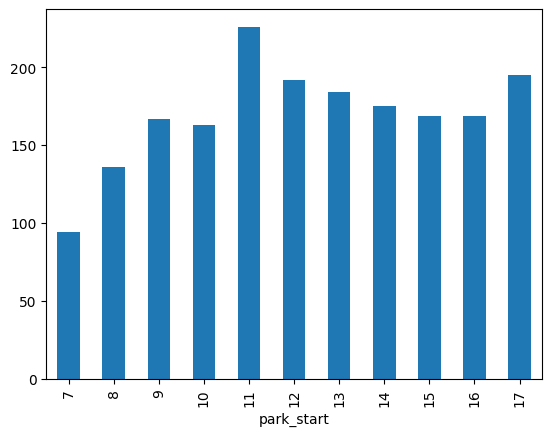

In [131]:
# no more 18 hour 
hour = idax1_loading_zones['park_start'].str.split(':').str[0].astype(int)
hour.value_counts().sort_index().plot.bar()

### Activity Type

In [132]:
idax1_loading_zones.columns

Index(['Event_NB', 'IDAX_Site_NB', 'ufl_block_id', 'ufl_blockface_id',
       'unitdesc', 'BLOCK_ID', 'ELMNTKEY', 'SPACETYPE', 'SPACE_NB',
       'Concatenated_SPACE_NB', 'Date', 'park_start', 'park_end',
       'total_duration', 'body_type', 'passenger_inout', 'driver_out',
       'activity_type', 'load_unload', 'handcart', 'CVLZ_permit_vid',
       'TNC_permit_vid', 'BLOCKID', 'PAIDAREA', 'day'],
      dtype='object')

In [133]:
counts = idax1_loading_zones['activity_type'].value_counts(dropna=False)
pd.DataFrame({
    "count": counts,
    "percent": (counts / counts.sum() * 100).round(1),
}).style.format({"percent": "{:.1f}%"})


,count,percent
activity_type,,
Private,1066,57.0%
Rideshare,205,11.0%
Parcel Carrier,161,8.6%
Food Delivery,156,8.3%
Goods Transport,91,4.9%
Service,77,4.1%
General Commercial (CM),71,3.8%
Truck Rental,17,0.9%
Other Transit,13,0.7%


In [134]:
activity_counts_by_area = pd.crosstab(idax1_loading_zones['activity_type'], idax1_loading_zones['PAIDAREA'])
activity_percent_by_area = activity_counts_by_area / activity_counts_by_area.sum() * 100

activity_by_area = pd.DataFrame()
for area in activity_counts_by_area.columns:
    activity_by_area[f"{area} (count)"] = activity_counts_by_area[area]
    activity_by_area[f"{area} (%)"] = activity_percent_by_area[area]

percent_columns = [column for column in activity_by_area.columns if column.endswith("(%)")]
activity_by_area.style.format({column: "{:.1f}%" for column in percent_columns})


,Belltown (count),Belltown (%),Denny Triangle (count),Denny Triangle (%)
activity_type,,,,
Construction,1,0.1%,0,0.0%
Emergency,3,0.3%,5,0.5%
Food Delivery,80,9.0%,76,7.7%
General Commercial (CM),44,5.0%,27,2.7%
Goods Transport,50,5.6%,41,4.2%
Other Transit,3,0.3%,10,1.0%
Parcel Carrier,99,11.1%,62,6.3%
Private,456,51.4%,610,62.1%
Public Transit,2,0.2%,2,0.2%


In [135]:
# cross tab
(pd.crosstab(idax1_loading_zones['body_type'],
             idax1_loading_zones['activity_type'],
             normalize='index',
             dropna=False) * 100).round(1)


activity_type,Construction,Emergency,Food Delivery,General Commercial (CM),Goods Transport,Other Transit,Parcel Carrier,Private,Public Transit,Rideshare,Service,Truck Rental
body_type,,,,,,,,,,,,
Bus,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
Bus/Other Transit,0.0,0.0,0.0,0.0,0.0,81.2,0.0,0.0,18.8,0.0,0.0,0.0
CM Pickup,0.0,0.0,3.7,7.4,0.0,0.0,0.0,0.0,0.0,0.0,88.9,0.0
Minivan,0.0,2.3,4.5,47.7,9.1,0.0,6.8,0.0,0.0,0.0,29.5,0.0
Motorcycle,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
Passenger Vehicle,0.0,0.4,10.1,0.5,0.0,0.0,3.4,71.5,0.0,13.8,0.3,0.0
Single Unit Truck,1.1,0.0,2.2,7.6,73.9,0.0,3.3,0.0,0.0,0.0,5.4,6.5
Step-Van,0.0,0.0,0.0,3.6,0.0,0.0,89.3,0.0,0.0,0.0,7.1,0.0
Trailer Truck,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0


In [136]:
# duration by activity type
d = idax1_loading_zones.copy()
d['dur_min'] = pd.to_timedelta(d['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60

(d.groupby('activity_type')['dur_min']
   .describe(percentiles=[.25, .5, .75, .9])
   .round(1)
   .sort_values('50%', ascending=False))


,count,mean,std,min,25%,50%,75%,90%,max
activity_type,,,,,,,,,
Service,77.0,58.8,97.7,0.1,8.6,25.0,68.8,108.5,534.7
Goods Transport,91.0,25.3,44.8,0.1,8.3,16.1,27.2,44.3,380.1
Truck Rental,17.0,24.3,24.7,3.1,5.5,14.1,35.0,53.7,92.9
Emergency,8.0,12.7,10.8,0.8,4.2,11.9,18.3,27.8,27.9
Parcel Carrier,161.0,17.7,23.2,0.4,4.6,9.4,21.1,43.6,161.5
General Commercial (CM),71.0,41.6,86.5,0.1,3.1,8.3,27.1,134.4,415.4
Public Transit,4.0,7.8,4.7,2.4,5.6,7.5,9.7,12.2,13.8
Food Delivery,156.0,10.7,24.4,0.0,3.1,5.4,9.5,16.9,252.2
Private,1066.0,16.7,44.1,0.0,1.0,4.7,13.0,40.0,521.1


### Duration

total records: 1061
                missing  percent
park_start            0      0.0
park_end              0      0.0
total_duration        0      0.0
count    1061.0
mean       16.7
std        44.2
min         0.0
50%         4.6
75%        13.0
90%        40.0
95%        67.2
99%       210.8
max       521.1
Name: duration_min, dtype: float64


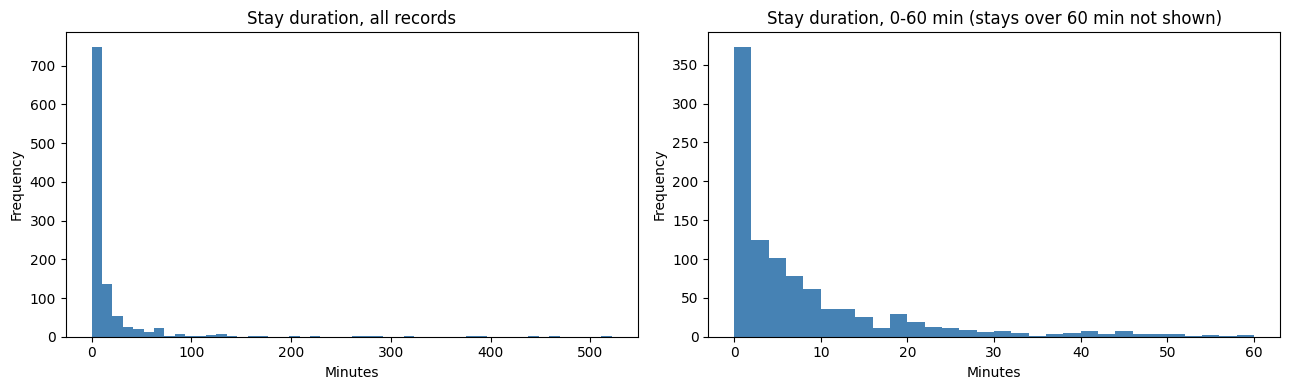

In [159]:
# private passenger vehicles in loading zones: how much is missing, and how long do they stay?
idax1_private_passenger = idax1_loading_zones[
    (idax1_loading_zones['activity_type'] == 'Private')
    & (idax1_loading_zones['body_type'] == 'Passenger Vehicle')
].copy()

# missing values are stored as the text '<null>'; turn them into real NaN
idax1_private_passenger = idax1_private_passenger.replace('<null>', pd.NA)

# how many are missing?
print("total records:", len(idax1_private_passenger))
time_columns = ['park_start', 'park_end', 'total_duration']
idax1_private_passenger_missing = pd.DataFrame({
    "missing": idax1_private_passenger[time_columns].isna().sum(),
    "percent": (idax1_private_passenger[time_columns].isna().mean() * 100).round(1),
})
print(idax1_private_passenger_missing)

# total_duration is text like '0:18:17' (h:mm:ss); convert to minutes
idax1_private_passenger['duration_min'] = pd.to_timedelta(
    idax1_private_passenger['total_duration']).dt.total_seconds() / 60

print(idax1_private_passenger['duration_min'].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

idax1_private_passenger['duration_min'].dropna().plot.hist(bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Stay duration, all records')
axes[0].set_xlabel('Minutes')

idax1_private_passenger['duration_min'].dropna().plot.hist(bins=range(0, 62, 2), ax=axes[1], color='steelblue')
axes[1].set_title('Stay duration, 0-60 min (stays over 60 min not shown)')
axes[1].set_xlabel('Minutes')

plt.tight_layout()
plt.show()



===== Belltown =====
total records: 453
                missing  percent
park_start            0      0.0
park_end              0      0.0
total_duration        0      0.0
count    453.0
mean      14.0
std       36.3
min        0.0
50%        4.1
75%       10.9
90%       33.9
95%       60.4
99%      134.6
max      440.0
Name: duration_min, dtype: float64


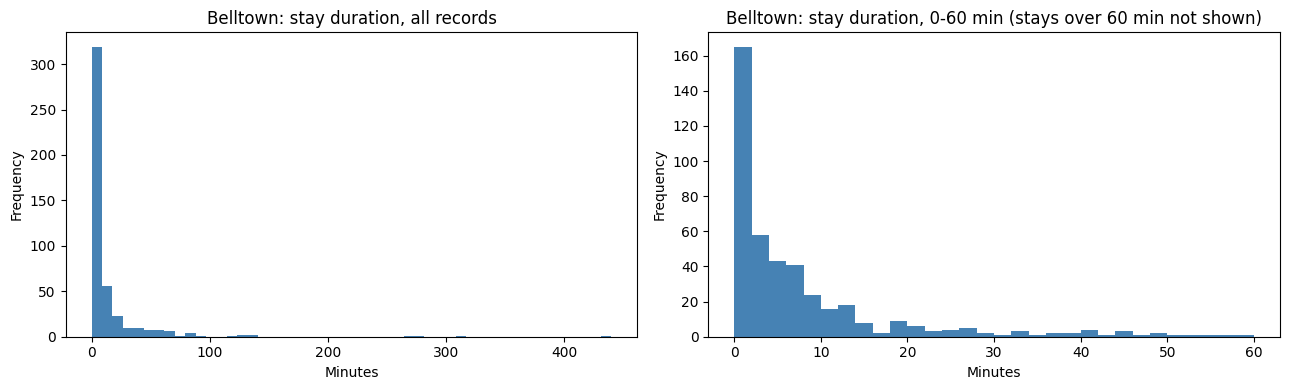


===== Denny Triangle =====
total records: 608
                missing  percent
park_start            0      0.0
park_end              0      0.0
total_duration        0      0.0
count    608.0
mean      18.8
std       49.2
min        0.0
50%        4.9
75%       15.1
90%       43.0
95%       71.2
99%      226.9
max      521.1
Name: duration_min, dtype: float64


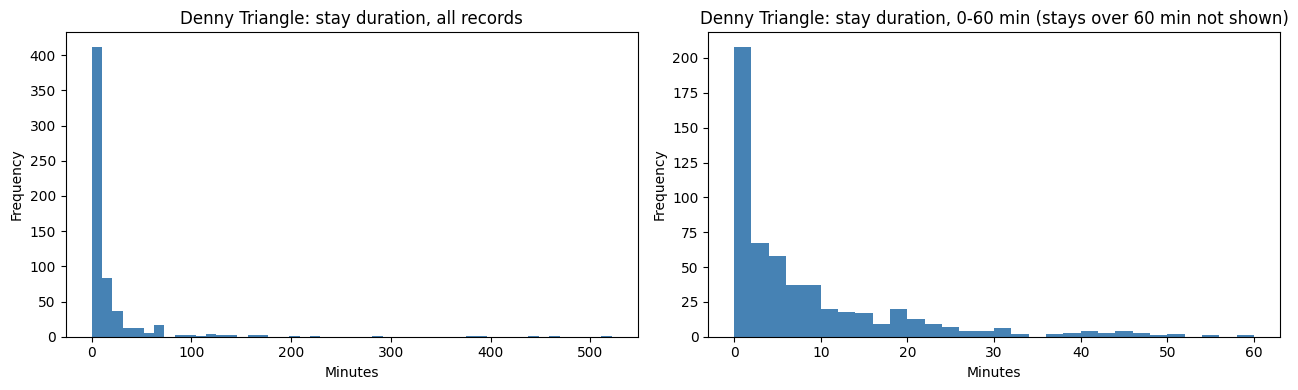

In [160]:
idax1_private_passenger_by_area = {}
time_columns = ['park_start', 'park_end', 'total_duration']

for area, area_rows in idax1_loading_zones.groupby('PAIDAREA'):
    idax1_private_passenger_in_area = area_rows[
        (area_rows['activity_type'] == 'Private')
        & (area_rows['body_type'] == 'Passenger Vehicle')
    ].copy()

    # missing values are stored as the text '<null>'; turn them into real NaN
    idax1_private_passenger_in_area = idax1_private_passenger_in_area.replace('<null>', pd.NA)

    print(f"\n===== {area} =====")
    print("total records:", len(idax1_private_passenger_in_area))
    idax1_private_passenger_in_area_missing = pd.DataFrame({
        "missing": idax1_private_passenger_in_area[time_columns].isna().sum(),
        "percent": (idax1_private_passenger_in_area[time_columns].isna().mean() * 100).round(1),
    })
    print(idax1_private_passenger_in_area_missing)

    # total_duration is text like '0:18:17' (h:mm:ss); convert to minutes
    idax1_private_passenger_in_area['duration_min'] = pd.to_timedelta(
        idax1_private_passenger_in_area['total_duration']).dt.total_seconds() / 60
    print(idax1_private_passenger_in_area['duration_min'].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    idax1_private_passenger_in_area['duration_min'].dropna().plot.hist(bins=50, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{area}: stay duration, all records')
    axes[0].set_xlabel('Minutes')

    idax1_private_passenger_in_area['duration_min'].dropna().plot.hist(bins=range(0, 62, 2), ax=axes[1], color='steelblue')
    axes[1].set_title(f'{area}: stay duration, 0-60 min (stays over 60 min not shown)')
    axes[1].set_xlabel('Minutes')

    plt.tight_layout()
    plt.show()

    idax1_private_passenger_by_area[area] = idax1_private_passenger_in_area


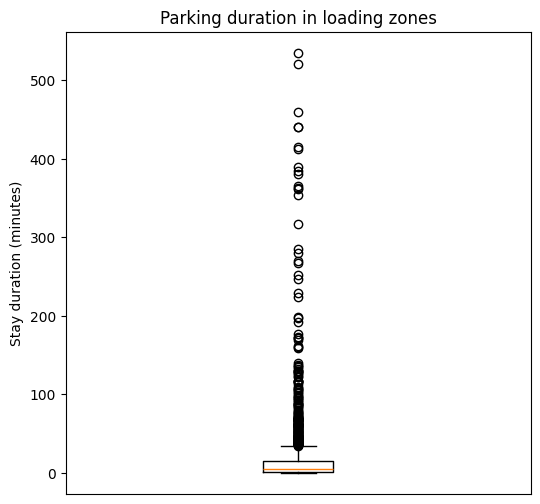

In [139]:
dur = pd.to_timedelta(idax1_loading_zones['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60

plt.figure(figsize=(6, 6))
plt.boxplot(dur.dropna())
plt.ylabel('Stay duration (minutes)')
plt.title('Parking duration in loading zones')
plt.xticks([])
plt.show()


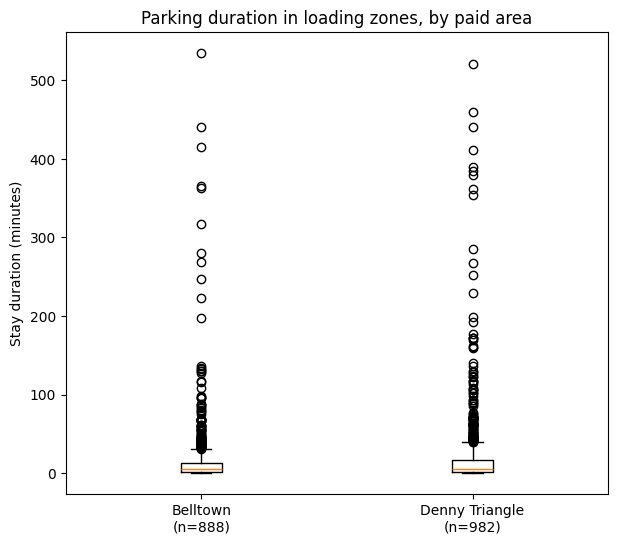

In [140]:
idax_loading_stay_minutes = idax1_loading_zones.copy()
idax_loading_stay_minutes['duration_min'] = pd.to_timedelta(
    idax_loading_stay_minutes['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60

stay_minutes_by_area = {
    area: area_rows['duration_min'].dropna()
    for area, area_rows in idax_loading_stay_minutes.groupby('PAIDAREA')
}

plt.figure(figsize=(7, 6))
plt.boxplot(stay_minutes_by_area.values(), tick_labels=[f"{area}\n(n={len(minutes)})" for area, minutes in stay_minutes_by_area.items()])
plt.ylabel('Stay duration (minutes)')
plt.title('Parking duration in loading zones, by paid area')
plt.show()


In [141]:
dur = pp['duration_min'].dropna()

print(f"30 min or more: {(dur >= 30).mean() * 100:.1f}%")
print(f"60 min or more: {(dur >= 60).mean() * 100:.1f}%")


30 min or more: 12.2%
60 min or more: 6.8%


In [142]:
stay_share_by_area = (pp.groupby('PAIDAREA')['duration_min']
    .agg(stays='count',
         share_30_min_or_more=lambda minutes: (minutes >= 30).sum() / minutes.count() * 100,
         share_60_min_or_more=lambda minutes: (minutes >= 60).sum() / minutes.count() * 100)
    .round(1))

stay_share_by_area.style.format({"share_30_min_or_more": "{:.1f}%", "share_60_min_or_more": "{:.1f}%"})


,stays,share_30_min_or_more,share_60_min_or_more
PAIDAREA,,,
Belltown,453,10.8%,5.3%
Denny Triangle,608,13.2%,7.9%


In [143]:
dur = pp['duration_min'].dropna()

bins = list(range(0, 65, 5)) + [float('inf')]
labels = [f"{b}-{b+5}" for b in range(0, 60, 5)] + ["60+"]
groups = pd.cut(dur, bins=bins, labels=labels, right=False)

counts = groups.value_counts().sort_index()
table = pd.DataFrame({
    "Stays": counts,
    "Percent": counts / counts.sum() * 100,
    "Cumulative %": counts.cumsum() / counts.sum() * 100,
})
table.index.name = "Duration (min)"

table.style.format({"Percent": "{:.1f}%", "Cumulative %": "{:.1f}%"})


,Stays,Percent,Cumulative %
Duration (min),,,
0-5,552,52.0%,52.0%
5-10,186,17.5%,69.6%
10-15,85,8.0%,77.6%
15-20,52,4.9%,82.5%
20-25,39,3.7%,86.1%
25-30,18,1.7%,87.8%
30-35,12,1.1%,89.0%
35-40,10,0.9%,89.9%
40-45,15,1.4%,91.3%


In [144]:
percent_by_area = pd.DataFrame({
    area: pd.cut(area_stays['duration_min'].dropna(), bins=bins, labels=labels, right=False)
            .value_counts(normalize=True).sort_index() * 100
    for area, area_stays in pp.groupby('PAIDAREA')
})
percent_by_area.index.name = "Duration (min)"
percent_by_area.style.format("{:.1f}%")


,Belltown,Denny Triangle
Duration (min),,
0-5,54.1%,50.5%
5-10,19.0%,16.4%
10-15,8.4%,7.7%
15-20,3.3%,6.1%
20-25,2.6%,4.4%
25-30,1.8%,1.6%
30-35,0.9%,1.3%
35-40,1.1%,0.8%
40-45,1.3%,1.5%


In [145]:
bins = list(range(0, 65, 5)) + [float('inf')]
labels = [f"{b}-{b+5}" for b in range(0, 60, 5)] + ["60+"]

for area, area_stays in pp.groupby('PAIDAREA'):
    stay_minutes = area_stays['duration_min'].dropna()
    duration_groups = pd.cut(stay_minutes, bins=bins, labels=labels, right=False)

    stays_per_group = duration_groups.value_counts().sort_index()
    duration_table = pd.DataFrame({
        "Stays": stays_per_group,
        "Percent": stays_per_group / stays_per_group.sum() * 100,
        "Cumulative %": stays_per_group.cumsum() / stays_per_group.sum() * 100,
    })
    duration_table.index.name = "Duration (min)"

    print(f"\n{area} ({len(stay_minutes)} stays)")
    display(duration_table.style.format({"Percent": "{:.1f}%", "Cumulative %": "{:.1f}%"}))



Belltown (453 stays)


,Stays,Percent,Cumulative %
Duration (min),,,
0-5,245,54.1%,54.1%
5-10,86,19.0%,73.1%
10-15,38,8.4%,81.5%
15-20,15,3.3%,84.8%
20-25,12,2.6%,87.4%
25-30,8,1.8%,89.2%
30-35,4,0.9%,90.1%
35-40,5,1.1%,91.2%
40-45,6,1.3%,92.5%



Denny Triangle (608 stays)


,Stays,Percent,Cumulative %
Duration (min),,,
0-5,307,50.5%,50.5%
5-10,100,16.4%,66.9%
10-15,47,7.7%,74.7%
15-20,37,6.1%,80.8%
20-25,27,4.4%,85.2%
25-30,10,1.6%,86.8%
30-35,8,1.3%,88.2%
35-40,5,0.8%,89.0%
40-45,9,1.5%,90.5%


1061 private passenger vehicles in loading zones
1061 with a park_start time


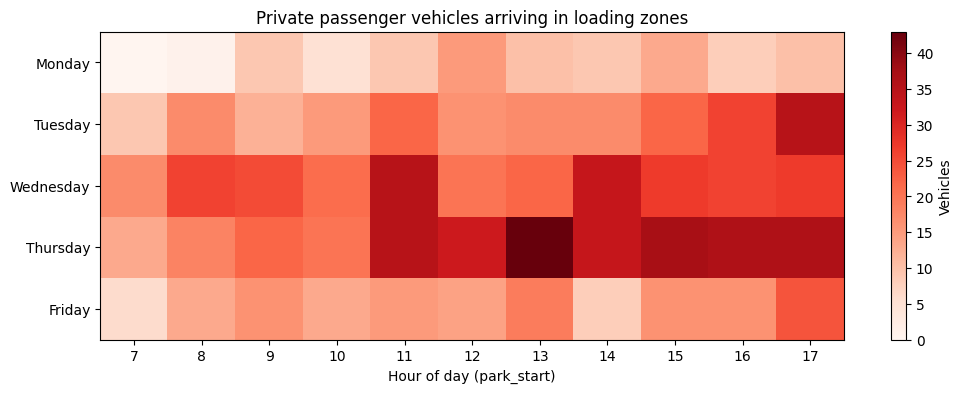

dow
Monday       1
Tuesday      5
Wednesday    6
Thursday     6
Friday       5
Name: Date, dtype: int64


In [146]:
# private passenger vehicles in loading zones: when do they arrive? (hour of day x day of week)
private_pass = idax1_loading_zones[
    (idax1_loading_zones['activity_type'] == 'Private')
    & (idax1_loading_zones['body_type'] == 'Passenger Vehicle')
].copy()
print(len(private_pass), "private passenger vehicles in loading zones")

# park_start is stored as the text '<null>' when missing; drop those rows
private_pass = private_pass[private_pass['park_start'] != '<null>']
print(len(private_pass), "with a park_start time")

private_pass['start'] = pd.to_datetime(private_pass['Date'] + ' ' + private_pass['park_start'])
private_pass['hour'] = private_pass['start'].dt.hour
private_pass['dow'] = private_pass['start'].dt.day_name()

order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
tbl = pd.crosstab(private_pass['dow'], private_pass['hour']).reindex(order).dropna(how='all')

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(tbl, aspect='auto', cmap='Reds')
ax.set_xticks(range(len(tbl.columns)), tbl.columns)
ax.set_yticks(range(len(tbl.index)), tbl.index)
ax.set_xlabel('Hour of day (park_start)')
ax.set_title('Private passenger vehicles arriving in loading zones')
plt.colorbar(im, label='Vehicles')
plt.show()

# survey days per weekday: counts are higher on weekdays that were surveyed more often
print(private_pass.groupby('dow')['Date'].nunique().reindex(tbl.index))

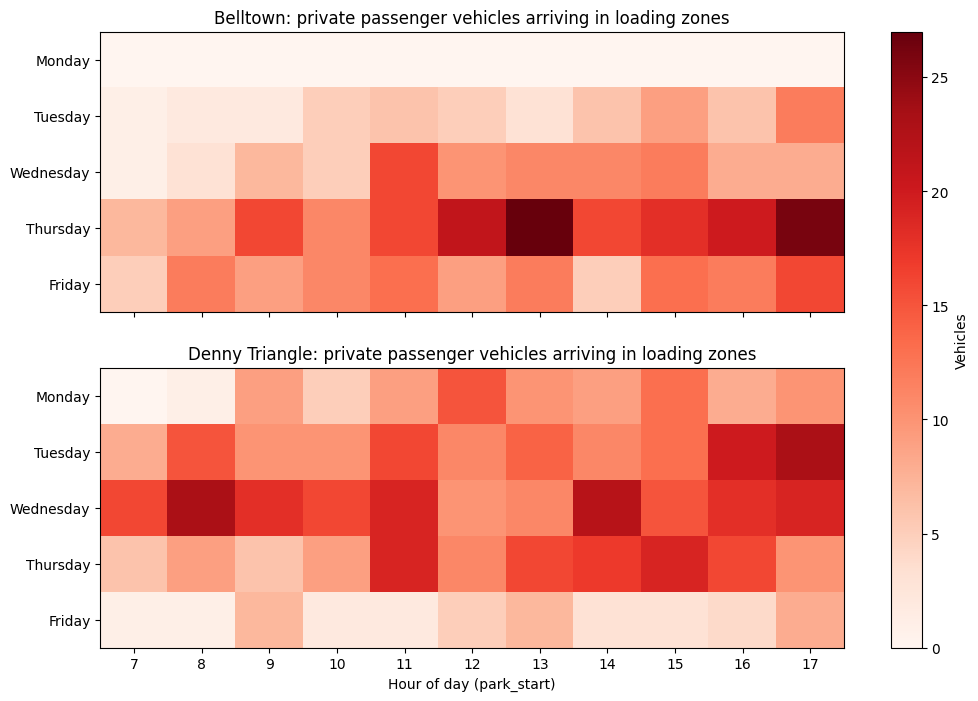

dow             Monday  Tuesday  Wednesday  Thursday  Friday
PAIDAREA                                                    
Belltown           NaN      3.0        5.0       4.0     4.0
Denny Triangle     1.0      2.0        2.0       2.0     1.0


In [147]:
private_passenger_arrivals = idax1_loading_zones[
    (idax1_loading_zones['activity_type'] == 'Private')
    & (idax1_loading_zones['body_type'] == 'Passenger Vehicle')
    & (idax1_loading_zones['park_start'] != '<null>')
].copy()

private_passenger_arrivals['start'] = pd.to_datetime(
    private_passenger_arrivals['Date'] + ' ' + private_passenger_arrivals['park_start'])
private_passenger_arrivals['hour'] = private_passenger_arrivals['start'].dt.hour
private_passenger_arrivals['dow'] = private_passenger_arrivals['start'].dt.day_name()

weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
hours = range(private_passenger_arrivals['hour'].min(), private_passenger_arrivals['hour'].max() + 1)

arrivals_by_area = {
    area: (pd.crosstab(area_rows['dow'], area_rows['hour'])
             .reindex(index=weekday_order, columns=hours, fill_value=0))
    for area, area_rows in private_passenger_arrivals.groupby('PAIDAREA')
}
highest_count = max(table.values.max() for table in arrivals_by_area.values())

fig, axes = plt.subplots(len(arrivals_by_area), 1, figsize=(12, 4 * len(arrivals_by_area)), sharex=True)
for axis, (area, arrivals_table) in zip(axes, arrivals_by_area.items()):
    image = axis.imshow(arrivals_table, aspect='auto', cmap='Reds', vmin=0, vmax=highest_count)
    axis.set_xticks(range(len(arrivals_table.columns)), arrivals_table.columns)
    axis.set_yticks(range(len(arrivals_table.index)), arrivals_table.index)
    axis.set_title(f'{area}: private passenger vehicles arriving in loading zones')
axes[-1].set_xlabel('Hour of day (park_start)')
fig.colorbar(image, ax=axes, label='Vehicles')
plt.show()

# survey days per weekday in each area
print(private_passenger_arrivals.groupby(['PAIDAREA', 'dow'])['Date'].nunique().unstack('dow')[weekday_order])


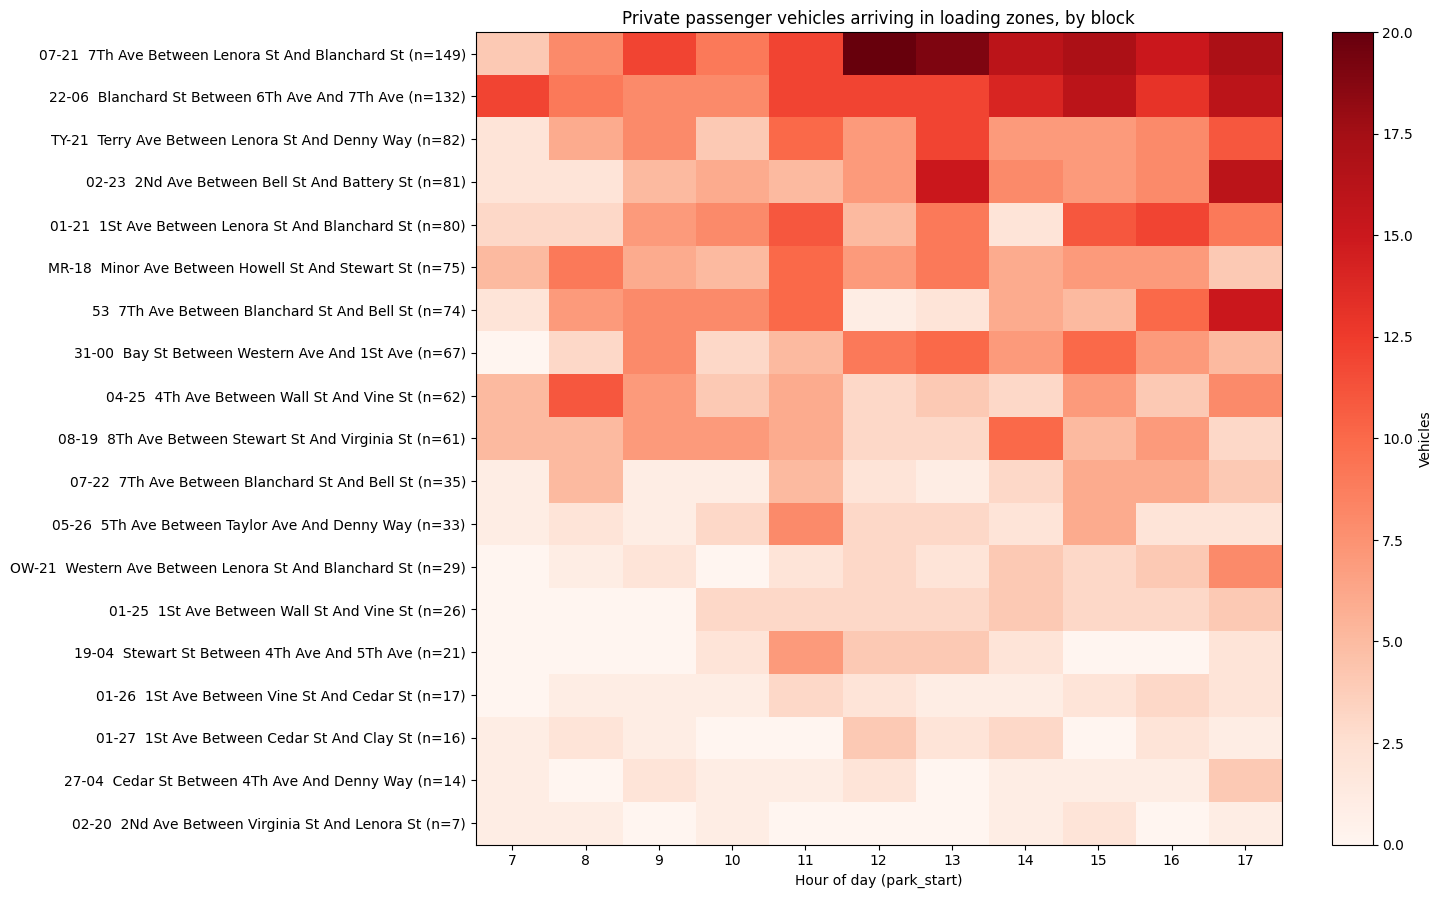

In [148]:
# same heatmap broken down by block: hour of day (x) by BLOCK_ID (y)
pp_block = idax1_loading_zones[
    (idax1_loading_zones['activity_type'] == 'Private')
    & (idax1_loading_zones['body_type'] == 'Passenger Vehicle')
    & (idax1_loading_zones['park_start'] != '<null>')
].copy()

pp_block['hour'] = pd.to_datetime(pp_block['park_start'], format='%H:%M:%S').dt.hour

tbl_block = pd.crosstab(pp_block['BLOCK_ID'], pp_block['hour'])
# fill in hours with no arrivals so every hour shows on the x-axis
tbl_block = tbl_block.reindex(columns=range(tbl_block.columns.min(), tbl_block.columns.max() + 1), fill_value=0)
# busiest blocks on top
tbl_block = tbl_block.loc[tbl_block.sum(axis=1).sort_values(ascending=False).index]

# y labels: BLOCK_ID plus the street description
desc = pp_block.groupby('BLOCK_ID')['unitdesc'].first().str.title()
ylabels = [f"{b}  {desc[b]} (n={tbl_block.loc[b].sum()})" for b in tbl_block.index]

fig, ax = plt.subplots(figsize=(13, 0.45 * len(tbl_block) + 2))
im = ax.imshow(tbl_block, aspect='auto', cmap='Reds')
ax.set_xticks(range(len(tbl_block.columns)), tbl_block.columns)
ax.set_yticks(range(len(tbl_block.index)), ylabels)
ax.set_xlabel('Hour of day (park_start)')
ax.set_title('Private passenger vehicles arriving in loading zones, by block')
plt.colorbar(im, label='Vehicles')
plt.show()

In [149]:
# duration by start hour
d = idax1_loading_zones.copy()
d['dur_min'] = pd.to_timedelta(d['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60
d['start_hour'] = d['park_start'].str.split(':').str[0].astype(int)

(d.groupby('start_hour')['dur_min']
   .describe(percentiles=[.25, .5, .75, .9])
   .round(1))


,count,mean,std,min,25%,50%,75%,90%,max
start_hour,,,,,,,,,
7,94.0,30.0,92.0,0.1,0.7,4.2,10.2,45.4,534.7
8,136.0,28.0,75.7,0.1,0.5,3.7,18.6,64.9,521.1
9,167.0,17.2,45.6,0.1,0.6,4.0,12.0,37.2,384.1
10,163.0,26.8,75.0,0.1,1.4,5.6,15.1,46.6,459.1
11,226.0,16.6,28.6,0.1,1.6,6.1,16.8,44.2,198.7
12,192.0,21.2,40.5,0.0,2.0,6.2,18.4,54.9,252.2
13,184.0,17.9,39.7,0.0,1.5,6.0,15.4,39.2,316.6
14,175.0,12.8,20.6,0.1,2.1,6.2,13.6,30.1,136.8
15,169.0,14.5,24.0,0.0,1.4,5.2,15.3,43.7,136.9


In [150]:
loading_6pm_with_duration = idax1_loading_zones.copy()
loading_6pm_with_duration['dur_min'] = pd.to_timedelta(
    loading_6pm_with_duration['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60
loading_6pm_with_duration['start_hour'] = loading_6pm_with_duration['park_start'].str.split(':').str[0].astype(int)

for area, area_rows in loading_6pm_with_duration.groupby('PAIDAREA'):
    print(f"\n{area} ({len(area_rows)} stays)")
    display(area_rows.groupby('start_hour')['dur_min']
                     .describe(percentiles=[.25, .5, .75, .9])
                     .round(1))



Belltown (888 stays)


,count,mean,std,min,25%,50%,75%,90%,max
start_hour,,,,,,,,,
7,31.0,35.1,113.2,0.2,0.9,5.7,9.4,26.8,534.7
8,49.0,32.7,73.6,0.1,1.2,7.2,22.8,82.4,415.4
9,72.0,18.9,44.1,0.1,1.3,6.3,15.4,39.8,269.3
10,76.0,24.6,70.1,0.1,1.7,4.9,14.0,42.5,440.0
11,105.0,13.8,22.5,0.1,1.3,4.6,15.6,39.9,108.2
12,98.0,14.6,22.7,0.1,2.0,6.2,15.8,33.9,129.4
13,105.0,16.2,39.2,0.0,1.2,6.1,13.4,36.2,316.6
14,91.0,10.8,15.1,0.2,2.4,5.8,11.8,28.6,86.1
15,80.0,12.5,23.6,0.0,1.4,4.5,10.1,36.1,136.9



Denny Triangle (982 stays)


,count,mean,std,min,25%,50%,75%,90%,max
start_hour,,,,,,,,,
7,63.0,27.4,80.4,0.1,0.4,3.6,13.7,54.8,411.8
8,87.0,25.4,77.1,0.1,0.4,1.5,13.6,46.6,521.1
9,95.0,15.9,46.9,0.1,0.5,2.9,9.3,31.8,384.1
10,87.0,28.7,79.4,0.1,1.4,6.7,15.3,50.4,459.1
11,121.0,19.0,32.9,0.1,2.7,7.5,18.3,46.0,198.7
12,94.0,28.0,52.4,0.0,2.7,6.2,19.8,89.5,252.2
13,79.0,20.3,40.4,0.1,1.9,5.8,18.6,49.4,284.9
14,84.0,15.0,25.2,0.1,2.0,6.4,17.0,30.5,136.8
15,89.0,16.3,24.4,0.1,1.4,5.5,18.8,46.2,108.9


### Weather
In some cases maybe weather matters? 

In [151]:
import requests

weather_response = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
    "latitude": 47.61, "longitude": -122.33,
    "start_date": "2024-04-30", "end_date": "2024-06-13",
    "hourly": "temperature_2m,precipitation",
    "timezone": "America/Los_Angeles",
}, timeout=60)
weather_response.raise_for_status()

weather_hourly = pd.DataFrame(weather_response.json()['hourly'])
weather_hourly['time'] = pd.to_datetime(weather_hourly['time'])
weather_hourly['date'] = weather_hourly['time'].dt.date
weather_hourly['hour'] = weather_hourly['time'].dt.hour

idax1_with_weather = idax1_loading_zones.copy()
idax1_with_weather['date'] = pd.to_datetime(idax1_with_weather['Date']).dt.date
idax1_with_weather['hour'] = idax1_with_weather['park_start'].str.split(':').str[0].astype(int)

idax1_with_weather = idax1_with_weather.merge(
    weather_hourly[['date', 'hour', 'temperature_2m', 'precipitation']],
    on=['date', 'hour'], how='left')

print(len(idax1_with_weather), idax1_with_weather['precipitation'].isna().sum(), "rows without weather")
idax1_with_weather['rain'] = idax1_with_weather['precipitation'] > 0

idax1_with_weather['duration_min'] = pd.to_timedelta(idax1_with_weather['total_duration']).dt.total_seconds() / 60
idax1_with_weather.groupby('rain')['duration_min'].describe().round(1)


1870 0 rows without weather


,count,mean,std,min,25%,50%,75%,max
rain,,,,,,,,
False,1583.0,17.2,45.7,0.0,1.2,5.2,14.0,534.7
True,287.0,21.3,46.8,0.1,1.2,5.7,19.6,440.3


In [152]:
idax1_with_weather['duration_min'] = pd.to_timedelta(idax1_with_weather['total_duration']).dt.total_seconds() / 60

idax1_with_weather.groupby('rain')['duration_min'].describe(percentiles=[.25, .5, .75, .9]).round(1)


,count,mean,std,min,25%,50%,75%,90%,max
rain,,,,,,,,,
False,1583.0,17.2,45.7,0.0,1.2,5.2,14.0,36.7,534.7
True,287.0,21.3,46.8,0.1,1.2,5.7,19.6,60.2,440.3


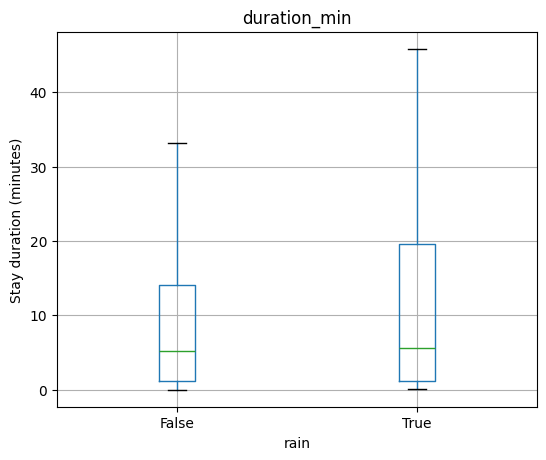

In [153]:
idax1_with_weather.boxplot(column='duration_min', by='rain', showfliers=False, figsize=(6, 5))
plt.suptitle('')
plt.ylabel('Stay duration (minutes)')
plt.show()


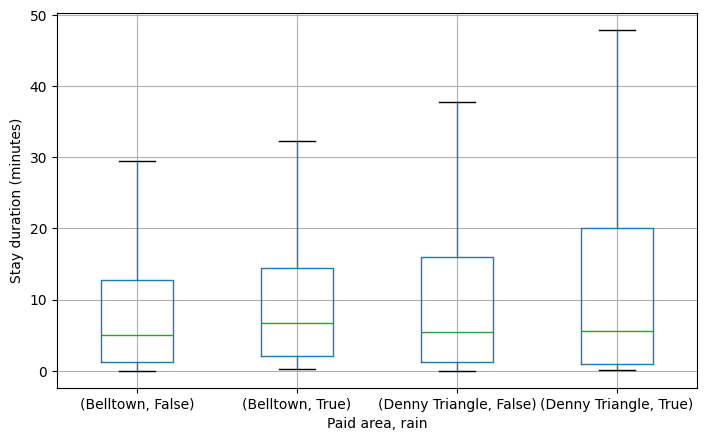

PAIDAREA        rain 
Belltown        False    838
                True      50
Denny Triangle  False    745
                True     237
Name: duration_min, dtype: int64

In [154]:
idax1_with_weather.boxplot(column='duration_min', by=['PAIDAREA', 'rain'], showfliers=False, figsize=(8, 5))
plt.suptitle('')
plt.title('')
plt.ylabel('Stay duration (minutes)')
plt.xlabel('Paid area, rain')
plt.show()

# how many stays are in each box
idax1_with_weather.groupby(['PAIDAREA', 'rain'])['duration_min'].count()


In [155]:
survey_dates = set(idax1_with_weather['date'])

survey_hours = weather_hourly[
    weather_hourly['date'].isin(survey_dates) & weather_hourly['hour'].between(7, 18)
].copy()

arrivals_per_hour = (idax1_with_weather.groupby(['date', 'hour'])
                     .size().rename('arrivals').reset_index())

survey_hours = survey_hours.merge(arrivals_per_hour, on=['date', 'hour'], how='left')
survey_hours['arrivals'] = survey_hours['arrivals'].fillna(0)
survey_hours['rain'] = survey_hours['precipitation'] > 0

survey_hours.groupby('rain')['arrivals'].agg(['count', 'mean', 'median'])


,count,mean,median
rain,,,
False,234,6.764957,6.0
True,42,6.833333,6.0


In [156]:
from scipy.stats import mannwhitneyu

dry_durations = idax1_with_weather.loc[~idax1_with_weather['rain'], 'duration_min'].dropna()
wet_durations = idax1_with_weather.loc[idax1_with_weather['rain'], 'duration_min'].dropna()
print(mannwhitneyu(dry_durations, wet_durations))

# not statiscially relevent. 

MannwhitneyuResult(statistic=np.float64(214794.5), pvalue=np.float64(0.14177426070518853))


In [157]:
bins = list(range(0, 65, 5)) + [float('inf')]
labels = [f"{b}-{b+5}" for b in range(0, 60, 5)] + ["60+"]

stays_with_duration = idax1_with_weather.dropna(subset=['duration_min']).copy()
stays_with_duration['duration_group'] = pd.cut(stays_with_duration['duration_min'],
                                               bins=bins, labels=labels, right=False)

stays_by_rain = pd.crosstab(stays_with_duration['duration_group'], stays_with_duration['rain']).reindex(labels, fill_value=0)
percent_by_rain = stays_by_rain / stays_by_rain.sum() * 100

duration_by_rain_table = pd.DataFrame({
    "No rain (stays)": stays_by_rain[False],
    "No rain (%)": percent_by_rain[False],
    "Rain (stays)": stays_by_rain[True],
    "Rain (%)": percent_by_rain[True],
})
duration_by_rain_table.index.name = "Duration (min)"

print(stays_by_rain.sum())   # total stays in each group

duration_by_rain_table.style.format({"No rain (%)": "{:.1f}%", "Rain (%)": "{:.1f}%"})


rain
False    1583
True      287
dtype: int64


,No rain (stays),No rain (%),Rain (stays),Rain (%)
Duration (min),,,,
0-5,785,49.6%,131,45.6%
5-10,284,17.9%,47,16.4%
10-15,138,8.7%,27,9.4%
15-20,85,5.4%,10,3.5%
20-25,61,3.9%,15,5.2%
25-30,36,2.3%,6,2.1%
30-35,24,1.5%,5,1.7%
35-40,22,1.4%,3,1.0%
40-45,24,1.5%,5,1.7%


In [158]:
long_stay_minutes = 30
long_stays = idax1_with_weather[idax1_with_weather['duration_min'] >= long_stay_minutes]
print(len(long_stays), "stays of", long_stay_minutes, "minutes or more")

for column in ['activity_type', 'body_type', 'load_unload', 'passenger_inout', 'driver_out']:
    long_share = long_stays[column].value_counts(normalize=True) * 100
    all_share = idax1_with_weather[column].value_counts(normalize=True) * 100
    comparison = pd.DataFrame({
        "Long stays (%)": long_share,
        "All stays (%)": all_share,
    }).round(1)
    print(f"\n{column}")
    print(comparison.sort_values("Long stays (%)", ascending=False))


245 stays of 30 minutes or more

activity_type
                         Long stays (%)  All stays (%)
activity_type                                         
Private                            53.1           57.0
Service                            13.9            4.1
Parcel Carrier                     11.8            8.6
Goods Transport                     7.8            4.9
General Commercial (CM)             6.9            3.8
Food Delivery                       2.4            8.3
Truck Rental                        2.4            0.9
Rideshare                           1.6           11.0
Construction                        NaN            0.1
Emergency                           NaN            0.4
Other Transit                       NaN            0.7
Public Transit                      NaN            0.2

body_type
                   Long stays (%)  All stays (%)
body_type                                       
Passenger Vehicle            60.0           79.4
Van                      

### Define illgeal parking 